# Figure 3: Anchor Compound Similarity Heatmaps

Compares anchor compounds across selected MoA clusters using both phenotypic embedding cosine similarity and chemical structural Tanimoto similarity.

This notebook generates:
1. Cosine similarity clustermap of selected MoA clusters (model embeddings)
2. Tanimoto structural diversity heatmap of selected MoA clusters
3. Tanimoto structural diversity heatmap with colorbar

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

from sklearn.metrics.pairwise import cosine_similarity
from matplotlib.patches import Rectangle
from phenocompass.data.featurization import mol_to_mf, canonicalize_smiles
from phenocompass.evaluation.metrics import compute_pairwise_tanimoto_similarity

from rdkit.Chem import AllChem
fpgen = AllChem.GetMorganGenerator(radius=3, fpSize=2048)
mf_featurizer = fpgen.GetCountFingerprint

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

# --- Output directories ---
BASE_DIR = str(REPO_ROOT)
DATA_DIR = os.path.join(BASE_DIR, "data", "anchor_visualizations")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "anchor_visualizations")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = False

# --- Tautomer canonicalization toggle ---
# When True (default), Tanimoto-based analyses use tautomer-canonicalized SMILES.
# Set to False to reproduce the originally published manuscript figures.
USE_TAUTOMER_CANONICALIZATION = True

# --- Matplotlib / font configuration ---
setup_publication_style(BASE_DIR)

if USE_TAUTOMER_CANONICALIZATION:
    print("USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)")
else:
    print("USE_TAUTOMER_CANONICALIZATION = False (original SMILES)")

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)


## 2. Load Data and Compute Similarity Matrices

In [2]:
# Load consolidated anchor compounds file
cluster_compounds_df = pd.read_csv(
    os.path.join(FINAL_DATA_DIR, "compound_annotations/anchor_compounds.tsv"),
    sep="\t"
)

cossim_cache = os.path.join(DATA_DIR, "anchor_viz_cosine_similarity.csv")
tanimoto_cache = os.path.join(DATA_DIR, "anchor_viz_tanimoto_similarity.csv")

if os.path.exists(cossim_cache) and os.path.exists(tanimoto_cache) and not FORCE_RECOMPUTE:
    reordered_cossim_df = pd.read_csv(cossim_cache, index_col=0)
    tanimoto_sim_df = pd.read_csv(tanimoto_cache, index_col=0)
    print("Loaded cached")
    print("Loaded cached")
else:
    img_representations_df = pd.read_parquet(
        os.path.join(FINAL_DATA_DIR, "embeddings/image/dino_image_embeddings.parquet")
    )

    # IMPORTANT: image-embedding lookup uses original canonical_SMILES (not
    # tautomer-canonicalized) because the embedding parquet is keyed on the
    # original strings.
    smiles = cluster_compounds_df["canonical_SMILES"].values
    cossim = cosine_similarity(img_representations_df.loc[smiles])

    cg = sns.clustermap(cossim, figsize=(1.2, 1.2))
    reordered_ind = cg.dendrogram_row.reordered_ind
    plt.close()

    reordered_smiles = smiles[reordered_ind]
    cossim_df = pd.DataFrame(cossim, index=smiles, columns=smiles)
    reordered_cossim_df = cossim_df.loc[reordered_smiles, reordered_smiles]

    # Tanimoto matrix: use canonicalized SMILES if toggle is on
    if USE_TAUTOMER_CANONICALIZATION:
        smiles_for_fp = [canonicalize_smiles(s) for s in reordered_smiles]
    else:
        smiles_for_fp = list(reordered_smiles)
    reordered_mf = [mol_to_mf(s, mf_featurizer) for s in smiles_for_fp]
    tanimoto_sim = compute_pairwise_tanimoto_similarity(reordered_mf)
    # Index/columns keep ORIGINAL SMILES to preserve downstream merge behavior
    tanimoto_sim_df = pd.DataFrame(tanimoto_sim, index=reordered_smiles, columns=reordered_smiles)

    reordered_cossim_df.to_csv(cossim_cache)
    tanimoto_sim_df.to_csv(tanimoto_cache)
    print("Cached to")
    print("Cached to")

mol_cluster_moa_dict = dict(zip(
    cluster_compounds_df["canonical_SMILES"],
    cluster_compounds_df["cluster_moa"]
))
reordered_compounds_df = pd.DataFrame({
    "SMILES": reordered_cossim_df.index.values,
    "cluster_moa": [mol_cluster_moa_dict[mol] for mol in reordered_cossim_df.index.values]
})

Loaded cached
Loaded cached


## 3. Cosine Similarity Clustermap

Figure already exists


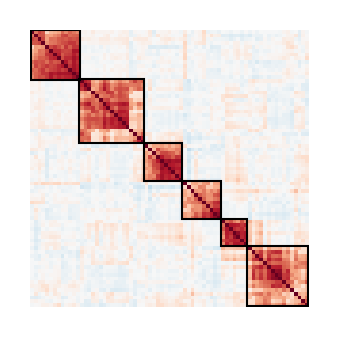

In [3]:
fig_path = os.path.join(FIGURE_DIR, "Fig2_selected_moas_clustermap.pdf")

plt.figure(figsize=(1.2, 1.2))
ax = sns.heatmap(reordered_cossim_df.values, vmin=-1, vmax=1, cmap="RdBu_r",
                 xticklabels=False, yticklabels=False, cbar=False)

current_idx = 0
for cluster_moa in reordered_compounds_df["cluster_moa"].unique():
    n_compounds = reordered_compounds_df[reordered_compounds_df["cluster_moa"] == cluster_moa].shape[0]
    if current_idx == 0:
        ax.add_patch(Rectangle((current_idx + 0.15, current_idx + 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    else:
        ax.add_patch(Rectangle((current_idx - 0.15, current_idx - 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    current_idx += n_compounds

save_figure(fig_path, FORCE_RECOMPUTE)

## 4. Structural Diversity Heatmaps

Figure already exists


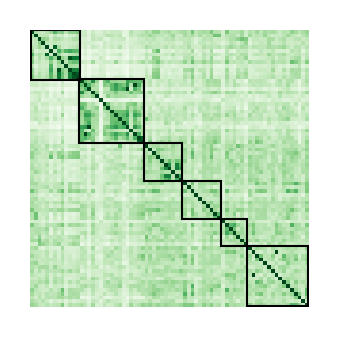

In [4]:
fig_path = os.path.join(FIGURE_DIR, "Fig2_structural_diversity_selected_moas.heatmap.pdf")

plt.figure(figsize=(1.2, 1.2))
ax = sns.heatmap(tanimoto_sim_df.values, cmap="Greens", vmin=0, vmax=0.5,
                 xticklabels=False, yticklabels=False, cbar=False)

current_idx = 0
for cluster_moa in reordered_compounds_df["cluster_moa"].unique():
    n_compounds = reordered_compounds_df[reordered_compounds_df["cluster_moa"] == cluster_moa].shape[0]
    if current_idx == 0:
        ax.add_patch(Rectangle((current_idx + 0.15, current_idx + 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    else:
        ax.add_patch(Rectangle((current_idx - 0.15, current_idx - 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    current_idx += n_compounds

save_figure(fig_path, FORCE_RECOMPUTE)

PI3K/mTOR: Max Tanimoto similarity: 0.48, Min Tanimoto similarity: 0.07
HDAC: Max Tanimoto similarity: 0.75, Min Tanimoto similarity: 0.03
MEK: Max Tanimoto similarity: 0.41, Min Tanimoto similarity: 0.13
JAK/ROCK: Max Tanimoto similarity: 0.28, Min Tanimoto similarity: 0.10
HSP90: Max Tanimoto similarity: 0.31, Min Tanimoto similarity: 0.09
CDK: Max Tanimoto similarity: 0.72, Min Tanimoto similarity: 0.09
Figure already exists


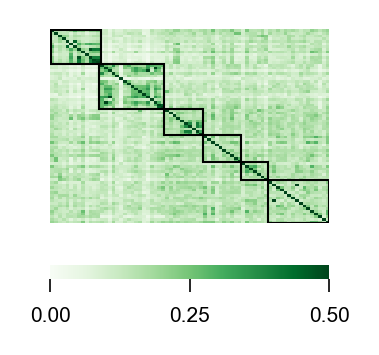

In [5]:
fig_path = os.path.join(FIGURE_DIR, "Fig2_structural_diversity_selected_moas.heatmap.colorbar.pdf")

plt.figure(figsize=(1.2, 1.2))
ax = sns.heatmap(tanimoto_sim_df.values, cmap="Greens", vmin=0, vmax=0.5,
                 xticklabels=False, yticklabels=False, cbar=True,
                 cbar_kws={"orientation": "horizontal"})
ax.tick_params(left=False, bottom=False)
cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.25, 0.5])

current_idx = 0
for cluster_moa in reordered_compounds_df["cluster_moa"].unique():
    n_compounds = reordered_compounds_df[reordered_compounds_df["cluster_moa"] == cluster_moa].shape[0]
    tanimoto_block = tanimoto_sim_df.values[current_idx:current_idx + n_compounds,
                                           current_idx:current_idx + n_compounds]
    tanimoto_triu = tanimoto_block[np.triu_indices(tanimoto_block.shape[0], k=1)]
    print("{}: Max Tanimoto similarity: {:.2f}, Min Tanimoto similarity: {:.2f}".format(
        cluster_moa, np.max(tanimoto_triu), np.min(tanimoto_triu)))
    if current_idx == 0:
        ax.add_patch(Rectangle((current_idx + 0.15, current_idx + 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    else:
        ax.add_patch(Rectangle((current_idx - 0.15, current_idx - 0.15), n_compounds, n_compounds,
                               fill=False, edgecolor='black', lw=0.5))
    current_idx += n_compounds

save_figure(fig_path, FORCE_RECOMPUTE)

In [6]:
# Save figure source data for manuscript reproducibility
# Convert similarity matrices to long format with compound and cluster metadata
fig_data_list = []

for row_smiles in reordered_cossim_df.index:
    row_moa = mol_cluster_moa_dict[row_smiles]
    for col_smiles in reordered_cossim_df.columns:
        col_moa = mol_cluster_moa_dict[col_smiles]
        fig_data_list.append({
            "row_compound": row_smiles,
            "col_compound": col_smiles,
            "row_moa": row_moa,
            "col_moa": col_moa,
            "cosine_similarity": reordered_cossim_df.loc[row_smiles, col_smiles],
            "tanimoto_similarity": tanimoto_sim_df.loc[row_smiles, col_smiles]
        })

anchor_fig_data_df = pd.DataFrame(fig_data_list)

fig_data_path = os.path.join(FIGURE_DIR, "Fig2_anchor_similarity_matrices_data.tsv")
save_figure_data(anchor_fig_data_df, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists
